# Cotton Doctor - one notebook, 10 classes (5 disease + 5 weed)
One model that finds cotton leaf diseases **and** cotton weeds.

Steps: 1 Setup - 2 Data - 3 Load images - 4 Build model - 5 Train - 6 Test - 7 Export to TFLite

**Before you start:** Runtime -> Change runtime type -> **T4 GPU**. Then Runtime -> Run all.
If the data is already on this session's disk, step 2 skips the download automatically.

## 1. Setup
Loads the tools. Google Drive is used to save the trained model, so Colab will ask permission.

In [ ]:
!pip install -q -U kagglehub

import json, shutil, random
from pathlib import Path
from collections import Counter
import numpy as np
import tensorflow as tf
from tensorflow.keras import layers, models
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
import kagglehub

from google.colab import drive
drive.mount('/content/drive')

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

DATA = Path("/content/cotton_data")                                  # prepared data (Colab disk)
MODEL_PATH  = "/content/drive/MyDrive/cotton_doctor_best.keras"      # best trained model
TFLITE_PATH = "/content/drive/MyDrive/cotton_doctor.tflite"          # model for the app
LABELS_PATH = "/content/drive/MyDrive/cotton_doctor_labels.json"     # class list for the app

print("GPU found:", tf.config.list_physical_devices('GPU'))

Mounted at /content/drive
GPU found: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 2. Data
If `/content/cotton_data/labels.json` already exists, this step is skipped.
Otherwise it downloads both Kaggle datasets (about 10.5 GB for the weeds, a few minutes), keeps the 10 classes, and splits them 70 / 15 / 15 into train / val / test **before** any augmentation.

- Disease: the `Original Dataset` folder only (not the augmented copies). Leaf Variegation is left out (only 116 images).
- Weed: the 5 biggest classes of CottonWeedID15.

In [ ]:
if (DATA / "labels.json").exists():
    print("Data already prepared. Skipping download and split.")
else:
    disease_root = Path(kagglehub.dataset_download("parthajyotiroyjoy/cotton-plant-disease-dataset"))
    weed_root    = Path(kagglehub.dataset_download("yuzhenlu/cottonweedid15"))

    DISEASE_SRC = disease_root / "Original Dataset"
    WEED_SRC    = weed_root / "CottonWeedID15"

    # (source folder, folder name in the download): clean class name
    CLASS_MAP = {
        (DISEASE_SRC, "Leaf Redding"):             "Disease_Leaf_Reddening",
        (DISEASE_SRC, "Curl Virus"):               "Disease_Curl_Virus",
        (DISEASE_SRC, "Herbicide Growth Damage"):  "Disease_Herbicide_Damage",
        (DISEASE_SRC, "Healthy Leaf"):             "Disease_Healthy",
        (DISEASE_SRC, "Bacterial Blight"):         "Disease_Bacterial_Blight",
        (WEED_SRC, "Morningglory"):                "Weed_Morningglory",
        (WEED_SRC, "Carpetweeds"):                 "Weed_Carpetweed",
        (WEED_SRC, "PalmerAmaranth"):              "Weed_Palmer_Amaranth",
        (WEED_SRC, "Waterhemp"):                   "Weed_Waterhemp",
        (WEED_SRC, "Purslane"):                    "Weed_Purslane",
    }
    for (src, folder), clean in CLASS_MAP.items():
        assert (src / folder).is_dir(), f"Missing folder: {src / folder}"

    IMG_EXT = {".jpg", ".jpeg", ".png", ".bmp"}
    files, labels = [], []
    for (src, folder), clean in CLASS_MAP.items():
        for p in sorted((src / folder).iterdir()):
            if p.suffix.lower() in IMG_EXT:
                files.append(p); labels.append(clean)
    print("Total images found:", len(files))

    # 70% train, then the other 30% split in half: val and test (stratified = same class mix in each)
    f_train, f_rest, y_train, y_rest = train_test_split(
        files, labels, test_size=0.30, stratify=labels, random_state=SEED)
    f_val, f_test, y_val, y_test = train_test_split(
        f_rest, y_rest, test_size=0.50, stratify=y_rest, random_state=SEED)

    shutil.rmtree(DATA, ignore_errors=True)
    for split, fs, ys in [("train", f_train, y_train), ("val", f_val, y_val), ("test", f_test, y_test)]:
        for f, y in zip(fs, ys):
            dst = DATA / split / y
            dst.mkdir(parents=True, exist_ok=True)
            shutil.copy(f, dst / f.name)

    # Class names (alphabetical = Keras order) and class weights (small classes count more)
    classes = sorted(p.name for p in (DATA / "train").iterdir())
    y_idx = []
    for i, c in enumerate(classes):
        y_idx += [i] * len(list((DATA / "train" / c).iterdir()))
    w = compute_class_weight("balanced", classes=np.arange(len(classes)), y=np.array(y_idx))
    json.dump({"classes": classes, "class_weight": {i: float(x) for i, x in enumerate(w)}},
              open(DATA / "labels.json", "w"), indent=2)
    print("Data prepared.")

100%|██████████| 258M/258M [00:05<00:00, 53.0MB/s]

Extracting files...


100%|██████████| 10.5G/10.5G [01:46<00:00, 106MB/s]

Extracting files...


Total images found: 5264
Data prepared.


In [ ]:
# Show how many images each class has in each part
info = json.load(open(DATA / "labels.json"))
CLASSES = info["classes"]
CLASS_WEIGHT = {int(k): v for k, v in info["class_weight"].items()}
NUM_CLASSES = len(CLASSES)

print(f"{'class':28s} {'train':>6s} {'val':>6s} {'test':>6s} {'weight':>7s}")
tot = Counter()
for i, c in enumerate(CLASSES):
    n = {s: len(list((DATA / s / c).iterdir())) for s in ["train", "val", "test"]}
    for s in n: tot[s] += n[s]
    print(f"{c:28s} {n['train']:6d} {n['val']:6d} {n['test']:6d} {CLASS_WEIGHT[i]:7.2f}")
print(f"{'TOTAL':28s} {tot['train']:6d} {tot['val']:6d} {tot['test']:6d}")

# Leak check: the same file must never be in two parts
seen = {}
for s in ["train", "val", "test"]:
    for p in (DATA / s).rglob("*"):
        if p.is_file():
            key = (p.parent.name, p.name)
            assert key not in seen, f"{key} is in both {seen[key]} and {s}"
            seen[key] = s
print("No overlap between train, val and test.")

class                         train    val   test  weight
Disease_Bacterial_Blight        175     38     37    2.11
Disease_Curl_Virus              302     65     64    1.22
Disease_Healthy                 180     38     39    2.05
Disease_Herbicide_Damage        196     42     42    1.88
Disease_Leaf_Reddening          404     87     87    0.91
Weed_Carpetweed                 534    114    115    0.69
Weed_Morningglory               780    167    168    0.47
Weed_Palmer_Amaranth            482    104    103    0.76
Weed_Purslane                   315     67     68    1.17
Weed_Waterhemp                  316     68     67    1.17
TOTAL                          3684    790    790
No overlap between train, val and test.


## 3. Load the images
Images are resized to 224 x 224. Only the **training** images get augmentation (random flips, rotation, zoom, contrast). We do not divide pixels by 255: EfficientNetV2 scales them inside the model.

In [ ]:
IMG_SIZE = (224, 224)
BATCH_SIZE = 32

def load(split, shuffle):
    return tf.keras.utils.image_dataset_from_directory(
        DATA / split, labels="inferred", label_mode="categorical",
        class_names=CLASSES,            # same order as labels.json
        image_size=IMG_SIZE, batch_size=BATCH_SIZE, shuffle=shuffle, seed=SEED)

train_ds = load("train", True)
val_ds   = load("val", False)
test_ds  = load("test", False)

augment = tf.keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.15),
    layers.RandomContrast(0.15),
])
AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.map(lambda x, y: (augment(x, training=True), y), num_parallel_calls=AUTOTUNE).prefetch(AUTOTUNE)
val_ds   = val_ds.prefetch(AUTOTUNE)
test_ds  = test_ds.prefetch(AUTOTUNE)

Found 3684 files belonging to 10 classes.
Found 790 files belonging to 10 classes.
Found 790 files belonging to 10 classes.


## 4. Build the model
EfficientNetV2B0 already knows general shapes and textures from ImageNet. We freeze most of it, unfreeze the **last 20 layers** so they can adjust to cotton, and add our own layers that output 10 probabilities. BatchNormalization layers stay frozen (the safe way to fine-tune).

In [ ]:
base = tf.keras.applications.EfficientNetV2B0(
    include_top=False, weights="imagenet",
    input_shape=IMG_SIZE + (3,), include_preprocessing=True)

base.trainable = True
for layer in base.layers[:-20]:
    layer.trainable = False
for layer in base.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

inputs = layers.Input(shape=IMG_SIZE + (3,))
x = base(inputs, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.BatchNormalization()(x)
x = layers.Dense(256, activation="relu")(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)
model = models.Model(inputs, outputs, name="cotton_doctor")

model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
              loss="categorical_crossentropy", metrics=["accuracy"])

trainable = sum(int(np.prod(w.shape)) for w in model.trainable_weights)
print(f"Trainable parameters: {trainable:,} of {model.count_params():,}")

24274472/24274472 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Trainable parameters: 1,143,354 of 6,254,938


## 5. Train
Up to 20 epochs (one epoch = one pass over all training images). Early stopping ends training if the validation loss does not improve for 4 epochs. The best version is saved to Drive. This is the slow step (about 3 minutes per epoch on a T4 GPU in our run).

In [ ]:
EPOCHS = 20

callbacks = [
    tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=4, restore_best_weights=True),
    tf.keras.callbacks.ModelCheckpoint(MODEL_PATH, monitor="val_loss", save_best_only=True),
]

history = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS,
                    class_weight=CLASS_WEIGHT, callbacks=callbacks)

Epoch 1/20
116/116 ━━━━━━━━━━━━━━━━━━━━ 239s 2s/step - accuracy: 0.5014 - loss: 1.4123 - val_accuracy: 0.7722 - val_loss: 0.9995
Epoch 2/20
116/116 ━━━━━━━━━━━━━━━━━━━━ 171s 1s/step - accuracy: 0.7698 - loss: 0.6191 - val_accuracy: 0.8570 - val_loss: 0.5438
Epoch 3/20
116/116 ━━━━━━━━━━━━━━━━━━━━ 171s 1s/step - accuracy: 0.8401 - loss: 0.4348 - val_accuracy: 0.8835 - val_loss: 0.3665
Epoch 4/20
116/116 ━━━━━━━━━━━━━━━━━━━━ 184s 2s/step - accuracy: 0.8705 - loss: 0.3528 - val_accuracy: 0.8975 - val_loss: 0.2946
Epoch 5/20
116/116 ━━━━━━━━━━━━━━━━━━━━ 182s 2s/step - accuracy: 0.8936 - loss: 0.2998 - val_accuracy: 0.9038 - val_loss: 0.2775
Epoch 6/20
116/116 ━━━━━━━━━━━━━━━━━━━━ 194s 1s/step - accuracy: 0.9058 - loss: 0.2584 - val_accuracy: 0.9228 - val_loss: 0.2405
Epoch 7/20
116/116 ━━━━━━━━━━━━━━━━━━━━ 172s 1s/step - accuracy: 0.9134 - loss: 0.2329 - val_accuracy: 0.9304 - val_loss: 0.2057
Epoch 8/20
116/116 ━━━━━━━━━━━━━━━━━━━━ 193s 1s/step - accuracy: 0.9273 - loss: 0.2023 - val_accu

## 6. Test
The test images were never used in training. This is the honest score.

Test accuracy: 95.57 %

                          precision    recall  f1-score   support

Disease_Bacterial_Blight      0.921     0.946     0.933        37
      Disease_Curl_Virus      1.000     0.984     0.992        64
         Disease_Healthy      1.000     1.000     1.000        39
Disease_Herbicide_Damage      1.000     1.000     1.000        42
  Disease_Leaf_Reddening      0.966     0.966     0.966        87
         Weed_Carpetweed      0.990     0.896     0.941       115
       Weed_Morningglory      0.975     0.946     0.961       168
    Weed_Palmer_Amaranth      0.935     0.971     0.952       103
           Weed_Purslane      0.942     0.956     0.949        68
          Weed_Waterhemp      0.833     0.970     0.897        67

                accuracy                          0.956       790
               macro avg      0.956     0.963     0.959       790
            weighted avg      0.958     0.956     0.956       790



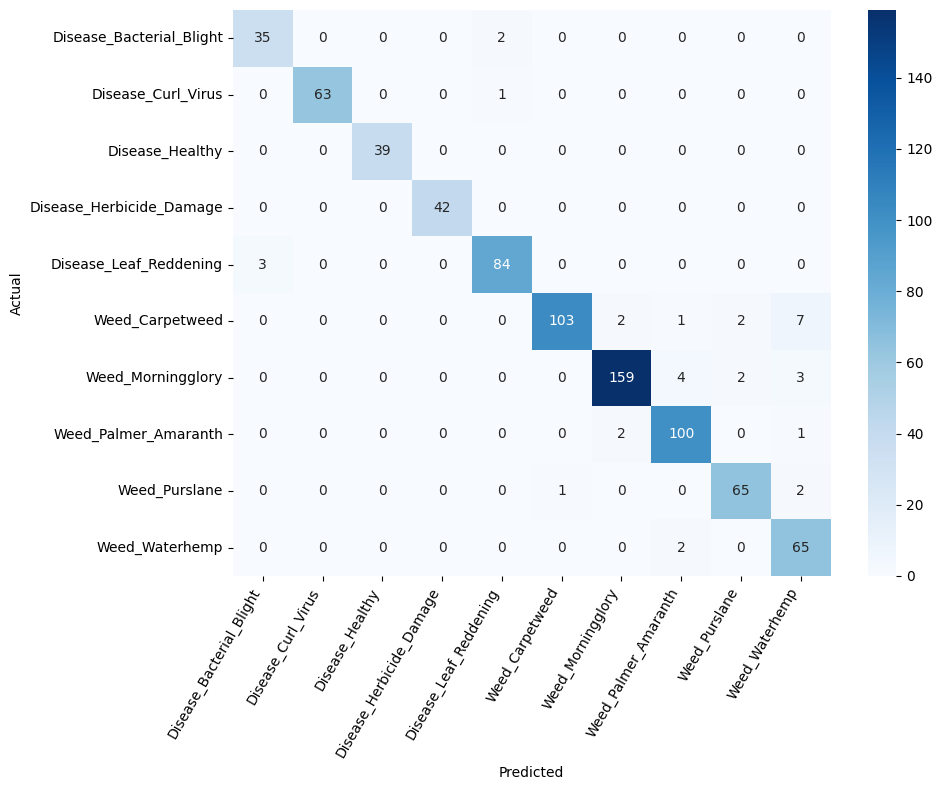

Disease <-> Weed mix-ups: 0 of 790 (0.00%)


In [ ]:
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

best = tf.keras.models.load_model(MODEL_PATH)

y_true, y_pred = [], []
for images, labels in test_ds:
    probs = best.predict(images, verbose=0)
    y_true += list(np.argmax(labels.numpy(), axis=1))
    y_pred += list(np.argmax(probs, axis=1))
y_true = np.array(y_true); y_pred = np.array(y_pred)

print("Test accuracy:", round((y_true == y_pred).mean() * 100, 2), "%\n")
print(classification_report(y_true, y_pred, target_names=CLASSES, digits=3))

cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=CLASSES, yticklabels=CLASSES)
plt.xlabel("Predicted"); plt.ylabel("Actual")
plt.xticks(rotation=60, ha="right"); plt.tight_layout(); plt.show()

is_disease = np.array([c.startswith("Disease_") for c in CLASSES])
mixups = is_disease[y_true] != is_disease[y_pred]
print(f"Disease <-> Weed mix-ups: {mixups.sum()} of {len(y_true)} ({mixups.mean() * 100:.2f}%)")

## 7. Export to TFLite
Converts the best model to the small file the app uses, checks it on the same test images, and saves it with the class list to Drive.
The model expects raw 0-255 pixel values (no division by 255, no preprocess_input).

In [ ]:
converter = tf.lite.TFLiteConverter.from_keras_model(best)
converter.optimizations = [tf.lite.Optimize.DEFAULT]
tflite_model = converter.convert()
with open(TFLITE_PATH, "wb") as f:
    f.write(tflite_model)
print("TFLite size:", round(len(tflite_model) / 1e6, 1), "MB")

interpreter = tf.lite.Interpreter(model_content=tflite_model)
interpreter.allocate_tensors()
inp = interpreter.get_input_details()[0]
out = interpreter.get_output_details()[0]

tfl_pred = []
for images, labels in test_ds:
    for img in images.numpy():
        interpreter.set_tensor(inp["index"], img[np.newaxis].astype(np.float32))
        interpreter.invoke()
        tfl_pred.append(int(np.argmax(interpreter.get_tensor(out["index"])[0])))
tfl_pred = np.array(tfl_pred)

print("Keras  test accuracy:", round((y_true == y_pred).mean() * 100, 2), "%")
print("TFLite test accuracy:", round((y_true == tfl_pred).mean() * 100, 2), "%")

shutil.copy(DATA / "labels.json", LABELS_PATH)
print("Saved to Drive: cotton_doctor.tflite and cotton_doctor_labels.json")

Saved artifact at '/tmp/tmpgvirxjzp'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name='input_layer_2')
Output Type:
  TensorSpec(shape=(None, 10), dtype=tf.float32, name=None)
Captures:
  136130873218384: TensorSpec(shape=(1, 1, 1, 3), dtype=tf.float32, name=None)
  136130873218192: TensorSpec(shape=(1, 1, 1, 3), dtype=tf.float32, name=None)
  136130873218576: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136130873218960: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136130873218768: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136130873219728: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136130873219152: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136130873217808: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136130873219920: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136130873219344: TensorSpec(shape=(), dtype=tf.resource, name=No

/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


Keras  test accuracy: 95.57 %
TFLite test accuracy: 95.82 %
Saved to Drive: cotton_doctor.tflite and cotton_doctor_labels.json
